# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** J.ABHILASH

**Roll Number:AP24110012142

**Date:09-10-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [3]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


# **Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"? **bold text**

*Your answer:*That makes sense because entropy measures how hard it is to guess the label. In a 70/30 case, the labels are more balanced, so it’s harder to predict correctly. In a 90/10 case, one label dominates, making the guess easier and the uncertainty lower.

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [6]:
# Write your answer here
import numpy as np

def entropy(counts):
    counts = np.array(counts, dtype=float)
    if counts.sum() == 0:
        return 0.0
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0
parent_counts = [8, 6]
entropy_parent = entropy(parent_counts)
left_counts = [6, 0]
entropy_left = entropy(left_counts)
right_counts = [2, 6]
entropy_right = entropy(right_counts)
weighted_entropy_after = (6/14) * entropy_left + (8/14) * entropy_right
info_gain = entropy_parent - weighted_entropy_after
print(f'Parent Entropy: {entropy_parent:.4f}')
print(f'Left Child Entropy: {entropy_left:.4f}')
print(f'Right Child Entropy: {entropy_right:.4f}')
print(f'Weighted Entropy After Split: {weighted_entropy_after:.4f}')
print(f'Information Gain: {info_gain:.4f}')

Parent Entropy: 0.9852
Left Child Entropy: 0.0000
Right Child Entropy: 0.8113
Weighted Entropy After Split: 0.4636
Information Gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [7]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [8]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [11]:
# 1. Compute the information gain for Outlook, Temperature and Humidity using info_gain.
gain_outlook = info_gain(tennis, 'Outlook')
gain_temp = info_gain(tennis, 'Temperature')
gain_humidity = info_gain(tennis, 'Humidity')

print('Information Gains:')
print(f'Gain(Outlook)    : {gain_outlook:.4f}')
print(f'Gain(Temperature): {gain_temp:.4f}')
print(f'Gain(Humidity)   : {gain_humidity:.4f}')
print('\nRoot attribute selected by ID3: Outlook')

print('\n--- Analyzing the "Sunny" branch ---')
sunny_branch = tennis[tennis['Outlook'] == 'Sunny']
display(sunny_branch)

print('Gains within the Sunny branch:')
for col in ['Temperature', 'Humidity', 'Wind']:
    print(f'Gain({col:11s}): {info_gain(sunny_branch, col):.4f}')

print('\n--- Analyzing the "Rain" branch ---')
rain_branch = tennis[tennis['Outlook'] == 'Rain']
display(rain_branch)

print('Gains within the Rain branch:')
for col in ['Temperature', 'Humidity', 'Wind']:
    print(f'Gain({col:11s}): {info_gain(rain_branch, col):.4f}')

Information Gains:
Gain(Outlook)    : 0.2467
Gain(Temperature): 0.0292
Gain(Humidity)   : 0.1518

Root attribute selected by ID3: Outlook

--- Analyzing the "Sunny" branch ---


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
10,Sunny,Mild,Normal,Strong,Yes


Gains within the Sunny branch:
Gain(Temperature): 0.5710
Gain(Humidity   ): 0.9710
Gain(Wind       ): 0.0200

--- Analyzing the "Rain" branch ---


,Outlook,Temperature,Humidity,Wind,Play
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
9,Rain,Mild,Normal,Weak,Yes
13,Rain,Mild,High,Strong,No


Gains within the Rain branch:
Gain(Temperature): 0.0200
Gain(Humidity   ): 0.0200
Gain(Wind       ): 0.9710


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:*A pure branch means that all the examples reaching that node belong to the same class. Since there’s no uncertainty left, the branch already perfectly classifies those cases. Splitting further wouldn’t change the outcome—it would just add unnecessary complexity without improving accuracy.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


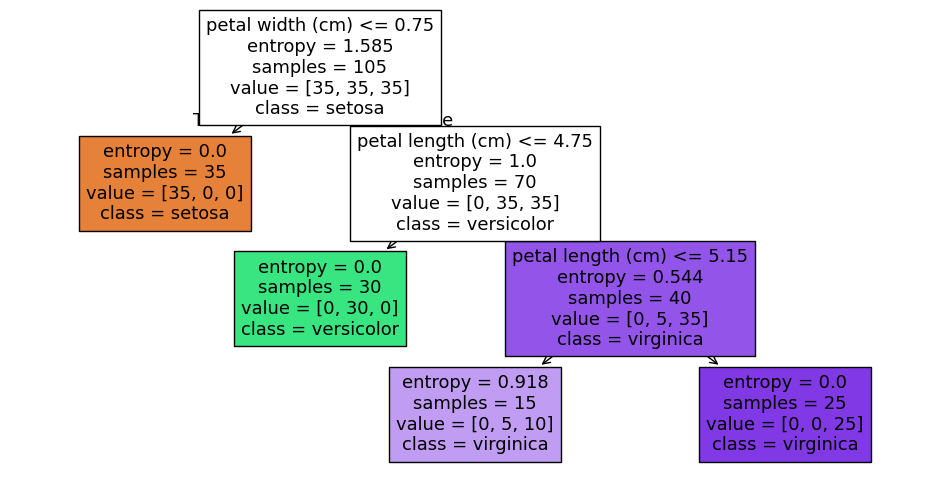

In [12]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


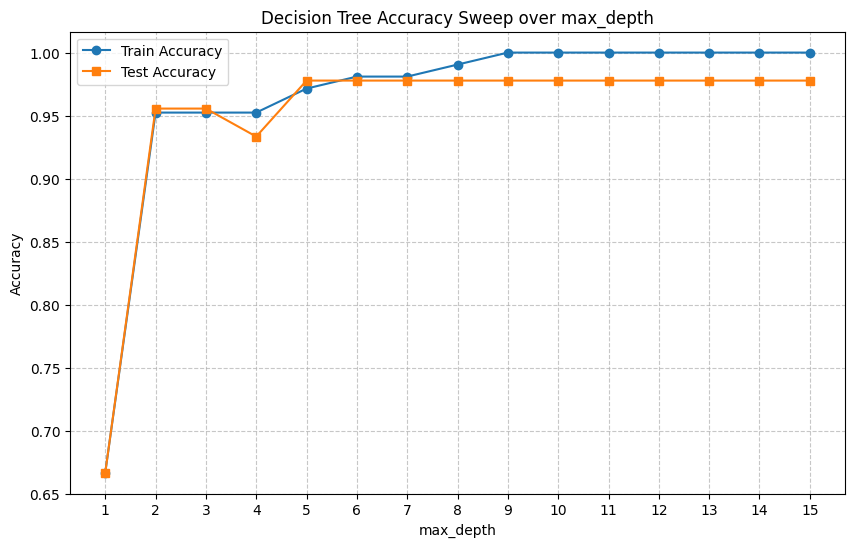

Best Test Accuracy: 0.9778 at max_depth = 5


In [13]:
import matplotlib.pyplot as plt

depths = list(range(1, 16))
train_accs = []
test_accs = []

for depth in depths:
    clf = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    clf.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))

    train_accs.append(train_acc)
    test_accs.append(test_acc)

# Find depth with the best test accuracy
best_idx = np.argmax(test_accs)
best_depth = depths[best_idx]
best_test_acc = test_accs[best_idx]

# Plotting the accuracies
plt.figure(figsize=(10, 6))
plt.plot(depths, train_accs, label='Train Accuracy', marker='o')
plt.plot(depths, test_accs, label='Test Accuracy', marker='s')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree Accuracy Sweep over max_depth')
plt.xticks(depths)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

print(f'Best Test Accuracy: {best_test_acc:.4f} at max_depth = {best_depth}')

**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:*At one extreme (very small max_depth, very small k, or very few components), the model is too simple: it underfits and misses important patterns.

At the other extreme (very large max_depth, very large k, or keeping too many components), the model is too complex: it overfits or keeps noise, reducing generalization.


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [14]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


1. Fully grown tree test accuracy: 0.8815
   Scaling is not needed because decision trees split on single features at thresholds (e.g., pixel_value <= threshold).
   Since they do not calculate distances between points, the scale of different features does not affect the splits.

2. Test accuracy at max_depth= 3: 0.5296
2. Test accuracy at max_depth= 6: 0.8537
2. Test accuracy at max_depth=10: 0.8796


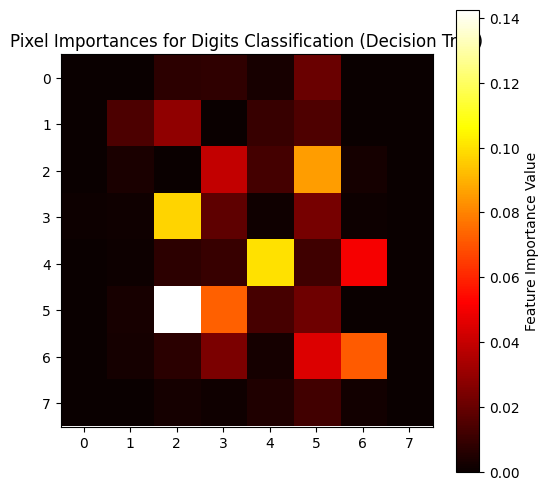


Based on the heatmap, the tree mostly relies on the central pixels (the center 4x4 region) and has almost zero reliance on the border pixels, which makes sense since digit drawings are usually centered and borders contain constant background color.


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. Fit a DecisionTreeClassifier on the unscaled Xd_train. Print test accuracy.
tree_full = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree_full.fit(Xd_train, yd_train)
acc_full = accuracy_score(yd_test, tree_full.predict(Xd_test))
print(f'1. Fully grown tree test accuracy: {acc_full:.4f}')
print("   Scaling is not needed because decision trees split on single features at thresholds (e.g., pixel_value <= threshold).")
print("   Since they do not calculate distances between points, the scale of different features does not affect the splits.\n")

# 2. Try max_depth values 3, 6, 10 and report test accuracy for each.
for depth in [3, 6, 10]:
    tree_depth = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    tree_depth.fit(Xd_train, yd_train)
    acc_depth = accuracy_score(yd_test, tree_depth.predict(Xd_test))
    print(f'2. Test accuracy at max_depth={depth:2d}: {acc_depth:.4f}')

# 3. Take tree.feature_importances_ (64 values), reshape to 8x8 and show it with plt.imshow.
importances = tree_full.feature_importances_
importances_grid = importances.reshape(8, 8)

plt.figure(figsize=(6, 6))
plt.imshow(importances_grid, cmap='hot', interpolation='nearest')
plt.colorbar(label='Feature Importance Value')
plt.title('Pixel Importances for Digits Classification (Decision Tree)')
plt.show()

print("\nBased on the heatmap, the tree mostly relies on the central pixels (the center 4x4 region) and has almost zero reliance on the border pixels, which makes sense since digit drawings are usually centered and borders contain constant background color.")

**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*One reason, shown by the importance map, is that the tree only focuses on a few pixel positions (those it splits on), while KNN uses the whole image pattern. That means the tree throws away a lot of useful information, so it struggles to capture the complex shapes of digits. KNN, by comparing full images, keeps more of the structure and tends to classify digits better.


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [16]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [18]:
from sklearn.tree import DecisionTreeClassifier, export_text

# 1. Fit a DecisionTreeClassifier on X_text, labels.
tree_text = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree_text.fit(X_text, labels)

# 2. Print the tree with export_text
tree_rules = export_text(tree_text, feature_names=vocab)
print("=== Decision Tree Structure ===")
print(tree_rules)

# 3. Predict 'the striker scored a goal' and an ambiguous sentence.
sentences_to_predict = [
    'the striker scored a goal',
    'the batsman and chef had a laptop match' # Example ambiguous sentence combining elements
]

for s in sentences_to_predict:
    vec = to_vector(s, vocab).reshape(1, -1)
    pred = tree_text.predict(vec)[0]
    print(f"Sentence: '{s}' -> Predicted Topic: '{pred}'")

=== Decision Tree Structure ===
|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

Sentence: 'the striker scored a goal' -> Predicted Topic: 'sports'
Sentence: 'the batsman and chef had a laptop match' -> Predicted Topic: 'cooking'


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:* That shows a tree trained on very little data is unstable and unreliable—it can overfit to noise and give splits that don’t generalize. You need more data or methods like pruning/ensembles to trust the results.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
